# Capstone Assignment: Mini-Courier Planner
### Integrated Parcel Prioritization, 0/1 Knapsack Dynamic Programming, Dijkstra Shortest Paths & TSP Route Optimization

**Mapped Course Outcomes:** CO1, CO2, CO3, CO4, CO5 (L5 - Evaluate)  
**Total Marks:** 100 (5 Phases × 20 Marks)

---

## 1. Phase 1: Courier Problem Design and Planning (20 Marks)

### 1.1 Problem Formulation
A last-mile courier dispatch hub receives a daily manifest of $N$ customer parcels with heterogeneous **weights** ($w_i \in \mathbb{Z}^+$ kg), **SLA delivery deadlines** ($d_i \in \mathbb{R}^+$ hours), **priority tiers** ($t_i \in \{1, 2, 3\}$), **priority-adjusted value scores** ($v_i \in \mathbb{Z}^+$), and **destination zone IDs** ($z_i \in V$). A courier van with fixed payload capacity $W$ (e.g., $W = 30\text{ kg}$) must:
1. **Prioritize Parcels (Phase 2A):** Rank all incoming parcels by urgency and SLA deadline using an optimal comparison sort (**Merge Sort**, $O(n \log n)$ stable).
2. **Optimize Box Filling (Phase 2B):** Select an indivisible subset of parcels $S \subseteq \{1, \dots, n\}$ such that $\sum_{i \in S} w_i \le W$ while maximizing total value $\sum_{i \in S} v_i$ via **Bottom-Up 0/1 Knapsack Dynamic Programming** ($O(n \cdot W)$).
3. **Compute Shortest Paths & Delivery Route (Phase 3):** Represent the city road network as a weighted undirected graph $G = (V, E, w)$, compute pairwise shortest paths between the Dispatch `HUB` and all active customer delivery stops using **Dijkstra's Algorithm** ($O((V + E)\log V)$ per source), and construct an ordered closed delivery tour using **Nearest-Neighbor TSP Approximation** ($O(k^2)$) with **2-Opt Local Search refinement** and **Held-Karp Exact TSP DP** ($O(k^2 2^k)$) verification.
4. **Evaluate Scalability & Runtime Performance (Phase 4 & 5):** Benchmark execution times, comparison counts, and optimality gaps across **Small ($N=20$)**, **Medium ($N=100$)**, and **Large ($N=500+$)** datasets.

Loaded Sample Parcel Manifest: 15 parcels (Total Weight = 86 kg)
Customer Graph Summary: |V| = 11 nodes, |E| = 22 undirected edges
----------------------------------------------------------------------------------
Node ID  | Zone Name              | Neighbors (Node: Distance km)
----------------------------------------------------------------------------------
HUB      | Central Dispatch Hub   | C1 (4.8km), C2 (6.2km), C3 (5.5km), C6 (5.3km), C8 (8.8km)
C1       | Downtown Market        | C2 (4.9km), C6 (9.4km), C8 (6.7km), C9 (4.2km), HUB (4.8km)
C2       | Civic Center           | C1 (4.9km), C10 (4.6km), C3 (4.7km), C9 (7.8km), HUB (6.2km)
C3       | Medical District       | C10 (5.7km), C2 (4.7km), C4 (5.1km), C5 (8.9km), HUB (5.5km)
C4       | Westside Mall          | C3 (5.1km), C5 (5.4km), C6 (9.1km)
C5       | Waterfront Plaza       | C3 (8.9km), C4 (5.4km), C6 (5.3km)
C6       | University Campus      | C1 (9.4km), C4 (9.1km), C5 (5.3km), C7 (5.8km), C8 (9.5km), HUB (5.3km)
C7

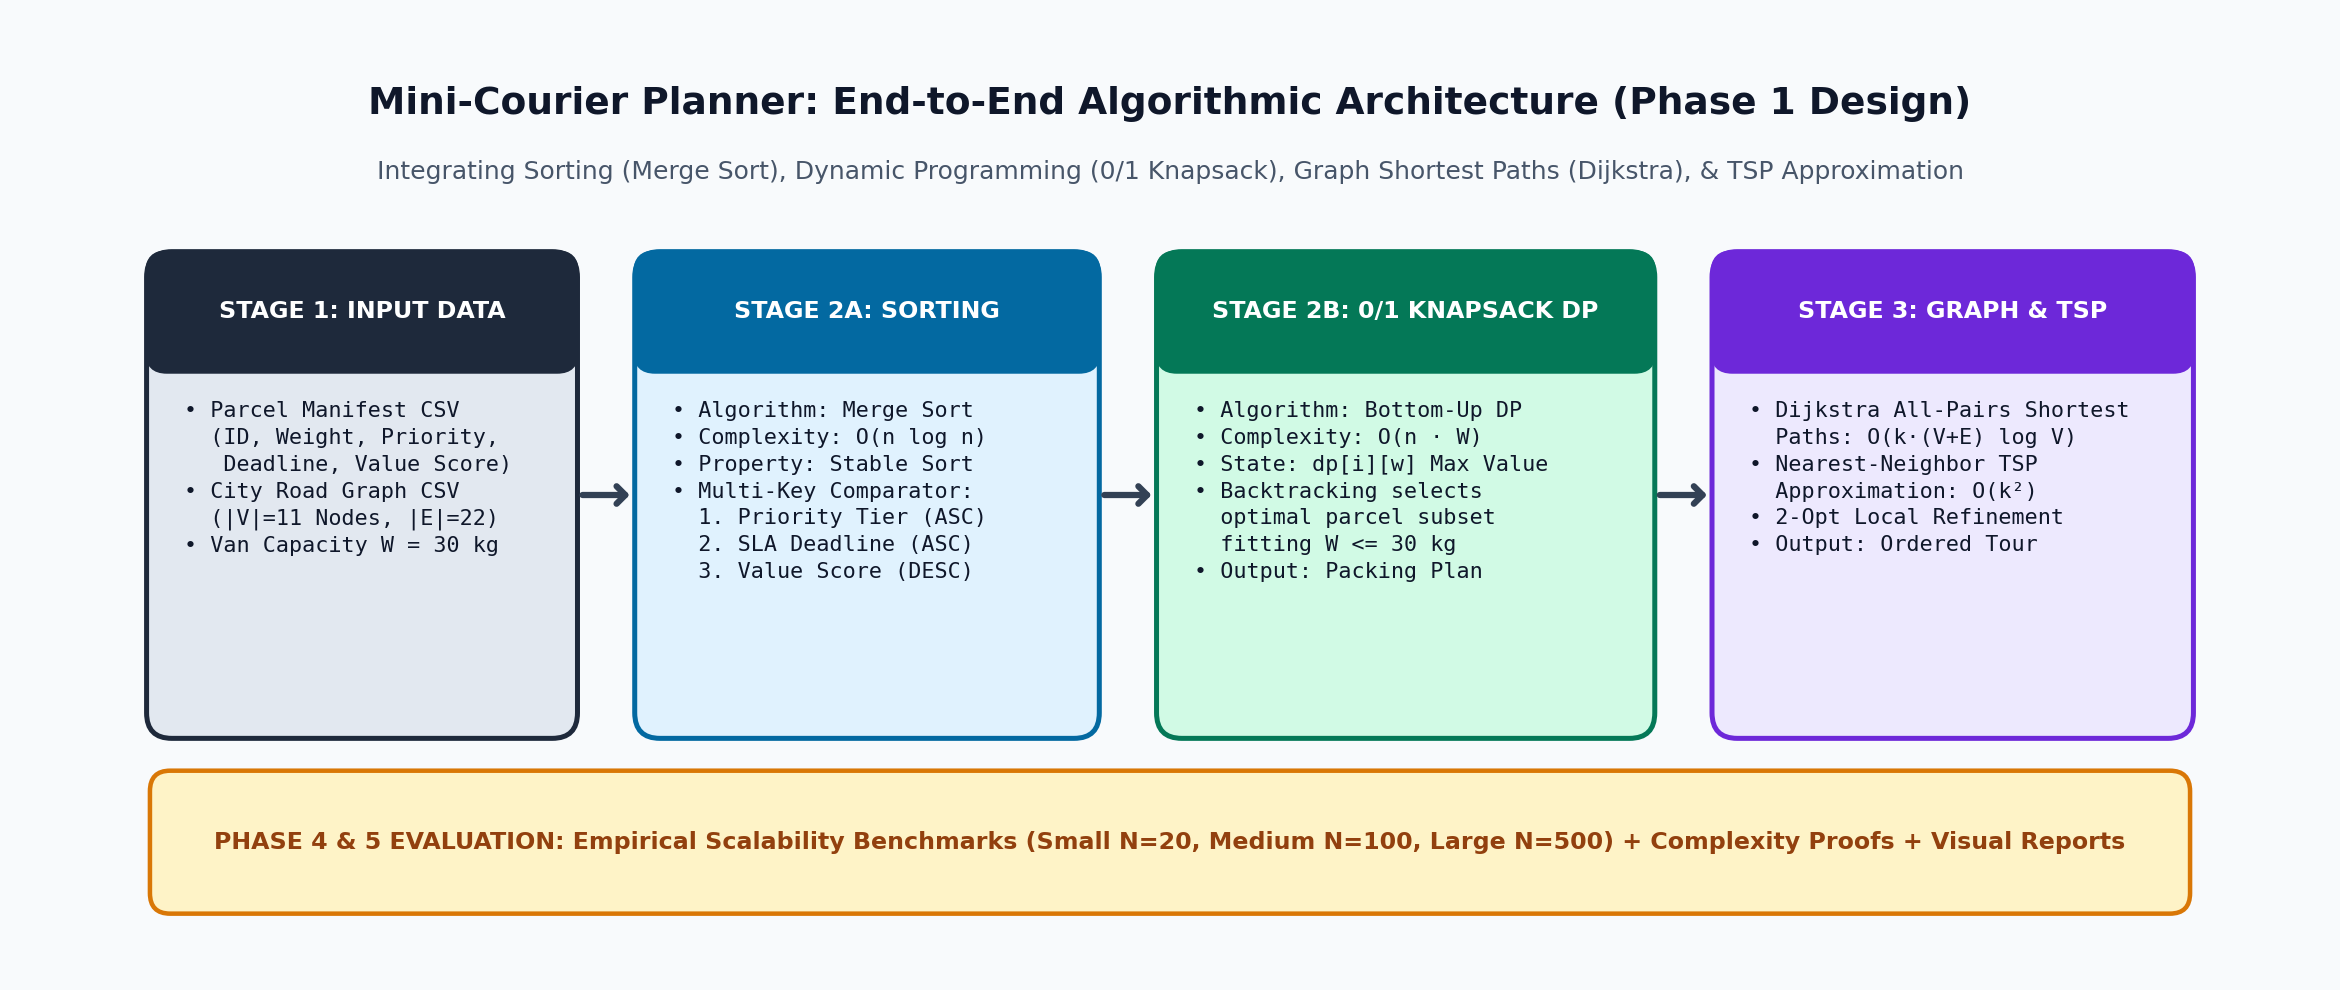

In [1]:
from pathlib import Path
import pandas as pd
from src.models import (
    Parcel, DeliveryNode, RoadEdge,
    load_parcels_from_csv, load_nodes_from_csv, load_edges_from_csv
)
from src.graph_routing import CustomerGraph
from src.visualizer import plot_phase1_architecture

PROJECT_ROOT = Path(".").resolve()
DATASETS_DIR = PROJECT_ROOT / "datasets"
IMAGES_DIR = PROJECT_ROOT / "images"

parcels = load_parcels_from_csv(DATASETS_DIR / "parcels_sample.csv")
nodes = load_nodes_from_csv(DATASETS_DIR / "graph_nodes.csv")
edges = load_edges_from_csv(DATASETS_DIR / "graph_edges.csv")
city_graph = CustomerGraph(nodes=nodes, edges=edges)

print(f"Loaded Sample Parcel Manifest: {len(parcels)} parcels (Total Weight = {sum(p.weight_kg for p in parcels)} kg)")
print(city_graph.format_adjacency_list())
plot_phase1_architecture(IMAGES_DIR / "phase1_system_architecture.png")

---
## 2. Phase 2: Package Prioritization and Box Filling (20 Marks)

### 2.1 Algorithm Selection Justification for Sorting
We compare four sorting algorithms on the parcel manifest:
- **Merge Sort (Selected Primary Algorithm):** Guarantees $O(n \log n)$ time complexity in worst, average, and best cases, and is **stable**—preserving arrival order when two parcels share the same priority tier and deadline.
- **Quick Sort (Median-of-3):** Fast in-cache average $O(n \log n)$, but unstable and susceptible to $O(n^2)$ worst-case partitions.
- **Heap Sort:** $O(n \log n)$ worst-case and $O(1)$ auxiliary memory, but unstable and exhibits poor cache locality due to pointer jumps in the binary heap.
- **Insertion Sort:** $O(n^2)$ quadratic baseline; efficient only for tiny or nearly-sorted manifests.

### 2.2 0/1 Knapsack Dynamic Programming Formulation
For van capacity $W = 30\text{ kg}$ and prioritized parcels $i \in \{1, \dots, n\}$ with weight $w_i$ and value score $v_i$:
$$dp[i][w] = \begin{cases} dp[i-1][w] & \text{if } w_i > w \\ \max\big(dp[i-1][w],\; v_i + dp[i-1][w - w_i]\big) & \text{if } w_i \le w \end{cases}$$
Unlike the **Greedy Value-Density Heuristic** ($v_i / w_i$), which cannot split indivisible parcels and leaves 3 kg of unused capacity ($27/30\text{ kg}$, value $= 730$), **0/1 Knapsack DP** achieves **100% capacity utilization ($30/30\text{ kg}$)** and the global optimum value of **785 (+55 points higher)**.

=== PHASE 2A: SORTED PARCEL MANIFEST (MERGE SORT) ===
Rank #01 | P013 | City General Hospital  | Dest: C3 (Medical District ) | CRITICAL (T1) | SLA:  1.0h | Wt:  6kg | Val: 140 | Density: 23.33
Rank #02 | P004 | Metro Legal Associates | Dest: C2 (Civic Center     ) | CRITICAL (T1) | SLA:  1.5h | Wt:  2kg | Val:  85 | Density: 42.50
Rank #03 | P001 | Apollo Diagnostics     | Dest: C3 (Medical District ) | CRITICAL (T1) | SLA:  2.0h | Wt:  4kg | Val:  95 | Density: 23.75
Rank #04 | P008 | Apex Financial Corp    | Dest: C2 (Civic Center     ) | CRITICAL (T1) | SLA:  2.0h | Wt:  3kg | Val:  90 | Density: 30.00
Rank #05 | P005 | Harbor View Pharmacy   | Dest: C5 (Waterfront Plaza ) | CRITICAL (T1) | SLA:  2.5h | Wt:  3kg | Val:  80 | Density: 26.67
Rank #06 | P014 | SilverOak Jewelers     | Dest: C9 (Uptown Boulevard ) | CRITICAL (T1) | SLA:  3.0h | Wt:  2kg | Val: 105 | Density: 52.50
Rank #07 | P002 | TechNova Labs          | Dest: C7 (IT Corridor      ) | CRITICAL (T1) | SLA:  3.5h | Wt:

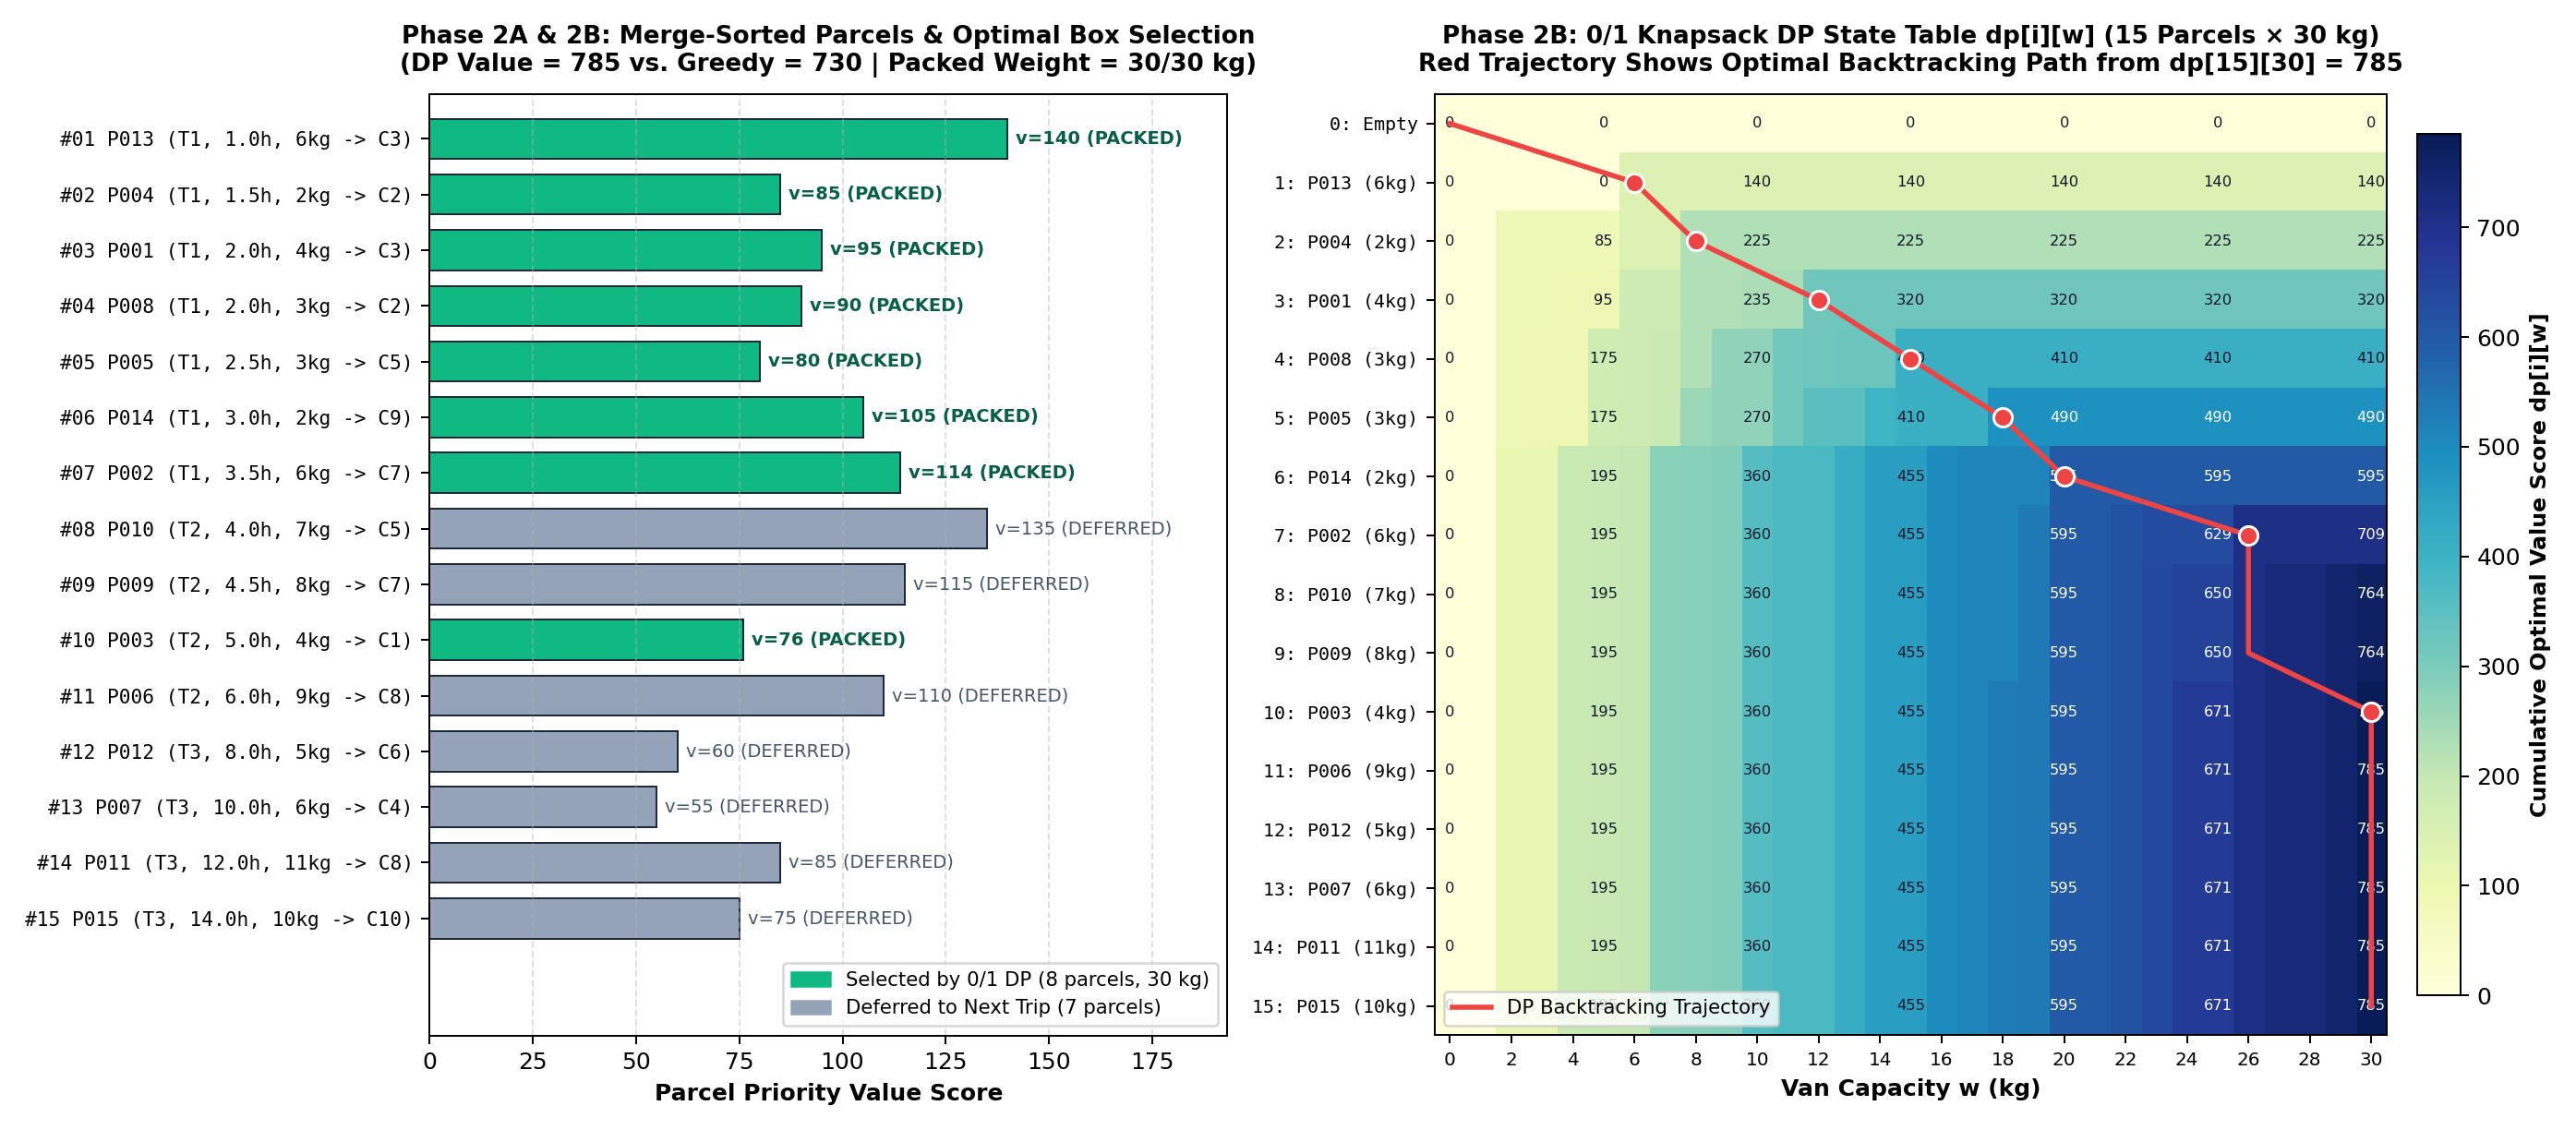

In [2]:
from src.sorting import (
    merge_sort_parcels, quick_sort_parcels, heap_sort_parcels, insertion_sort_parcels
)
from src.knapsack_dp import (
    solve_knapsack_01_dp, solve_knapsack_1d_optimized,
    solve_knapsack_greedy_heuristic, format_dp_table_ascii
)
from src.visualizer import plot_phase2_knapsack_and_prioritization

VAN_CAPACITY_KG = 30

# Phase 2A: Sort parcels by (priority_tier ASC, deadline_hrs ASC, -value_score ASC)
merge_res = merge_sort_parcels(parcels, mode="deadline_priority")
quick_res = quick_sort_parcels(parcels, mode="deadline_priority")
heap_res = heap_sort_parcels(parcels, mode="deadline_priority")
insert_res = insertion_sort_parcels(parcels, mode="deadline_priority")
sorted_parcels = merge_res.sorted_parcels

print("=== PHASE 2A: SORTED PARCEL MANIFEST (MERGE SORT) ===")
for rank, p in enumerate(sorted_parcels, 1):
    print(f"Rank #{rank:02d} | {p.parcel_id} | {p.customer_name:<22} | Dest: {p.destination_id} ({p.destination_name:<17}) "
          f"| {p.priority_label} | SLA: {p.deadline_hrs:>4.1f}h | Wt: {p.weight_kg:>2d}kg | Val: {p.value_score:>3d} | Density: {p.value_density:>5.2f}")

print("\nSorting Algorithm Comparison on Manifest:")
for res in [merge_res, quick_res, heap_res, insert_res]:
    print(f"  - {res.algorithm_name:<34}: Time = {res.execution_time_ms:.4f} ms | Comparisons = {res.comparisons_count}")

# Phase 2B: 0/1 Knapsack Dynamic Programming vs Greedy Heuristic
dp_2d_res = solve_knapsack_01_dp(sorted_parcels, capacity_kg=VAN_CAPACITY_KG, store_table=True)
dp_1d_res = solve_knapsack_1d_optimized(sorted_parcels, capacity_kg=VAN_CAPACITY_KG)
greedy_res = solve_knapsack_greedy_heuristic(sorted_parcels, capacity_kg=VAN_CAPACITY_KG)

print("\n=== PHASE 2B: 0/1 KNAPSACK DYNAMIC PROGRAMMING TABLE (SAMPLED AT 3 KG STEPS) ===")
print(format_dp_table_ascii(sorted_parcels, dp_2d_res.dp_table, step=3))

print(f"\nOptimal 0/1 DP Selected Parcels ({len(dp_2d_res.selected_parcels)} items, {dp_2d_res.total_weight_kg}/{VAN_CAPACITY_KG} kg = {dp_2d_res.utilization_pct}%):")
print("  Selected :", [f"{p.parcel_id} ({p.weight_kg}kg, v={p.value_score} -> {p.destination_id})" for p in dp_2d_res.selected_parcels])
print("  Deferred :", [f"{p.parcel_id} ({p.weight_kg}kg, v={p.value_score})" for p in dp_2d_res.deferred_parcels])
print(f"  2D DP Optimal Value = {dp_2d_res.total_value_score} ({dp_2d_res.execution_time_ms:.4f} ms) | "
      f"1D DP Optimal Value = {dp_1d_res.total_value_score} ({dp_1d_res.execution_time_ms:.4f} ms) | "
      f"Greedy Heuristic Value = {greedy_res.total_value_score} ({greedy_res.total_weight_kg}/{VAN_CAPACITY_KG} kg)")

plot_phase2_knapsack_and_prioritization(
    sorted_parcels, dp_2d_res, greedy_res, IMAGES_DIR / "phase2_knapsack_and_prioritization.png"
)

---
## 3. Phase 3: Route Maker and Graph Processing (20 Marks)

### 3.1 Graph Representation & Dijkstra's Shortest Path Algorithm
- **Graph Representation:** The city road network is stored as an **Adjacency List** (`dict[node_id, list[(neighbor_id, distance_km, road_name)]]`) with $|V| = 11$ nodes (`HUB` + `C1..C10`) and $|E| = 22$ bidirectional weighted road segments. For sparse road networks ($E = O(V)$), adjacency lists require $O(V + E)$ space compared to $O(V^2)$ for adjacency matrices.
- **All-Pairs Active Stop Shortest Paths via Dijkstra:** Using a binary min-heap priority queue (`heapq`), Dijkstra's algorithm computes shortest paths from `HUB` and each required customer stop in $O((V + E)\log V)$ time, uncovering multi-hop road paths (such as `C5 -> C6 -> C7` of length $11.10\text{ km}$ and `C7 -> C6 -> HUB` of length $11.10\text{ km}$).
- **Nearest-Neighbor TSP Approximation & 2-Opt Refinement:** Starting at `HUB`, the Nearest-Neighbor heuristic greedily visits the closest unvisited delivery stop in $O(k^2)$ time, producing the tour `HUB -> C1 -> C9 -> C2 -> C3 -> C5 -> C7 -> HUB` ($52.60\text{ km}$). Applying **2-Opt local search** uncrosses the `C9 -> C2` transition to achieve the exact **Held-Karp optimal tour length of $51.20\text{ km}$**.

=== PHASE 3A: DIJKSTRA SHORTEST PATHS FROM CENTRAL DISPATCH HUB ===
  HUB -> HUB  (Central Dispatch Hub ) :  0.00 km | Path: HUB
  HUB -> C1   (Downtown Market      ) :  4.80 km | Path: HUB -> C1
  HUB -> C6   (University Campus    ) :  5.30 km | Path: HUB -> C6
  HUB -> C3   (Medical District     ) :  5.50 km | Path: HUB -> C3
  HUB -> C2   (Civic Center         ) :  6.20 km | Path: HUB -> C2
  HUB -> C8   (Industrial Park      ) :  8.80 km | Path: HUB -> C8
  HUB -> C9   (Uptown Boulevard     ) :  9.00 km | Path: HUB -> C1 -> C9
  HUB -> C4   (Westside Mall        ) : 10.60 km | Path: HUB -> C3 -> C4
  HUB -> C5   (Waterfront Plaza     ) : 10.60 km | Path: HUB -> C6 -> C5
  HUB -> C10  (Greenfield Suburb    ) : 10.80 km | Path: HUB -> C2 -> C10
  HUB -> C7   (IT Corridor          ) : 11.10 km | Path: HUB -> C6 -> C7

=== PHASE 3B: NEAREST-NEIGHBOR TSP DELIVERY ROUTE BREAKDOWN ===
  Leg #1: HUB -> C1  |  4.80 km | Road Path: HUB -> C1          | Drop-off: P003 (4kg)
  Leg #2:  C1 -> C

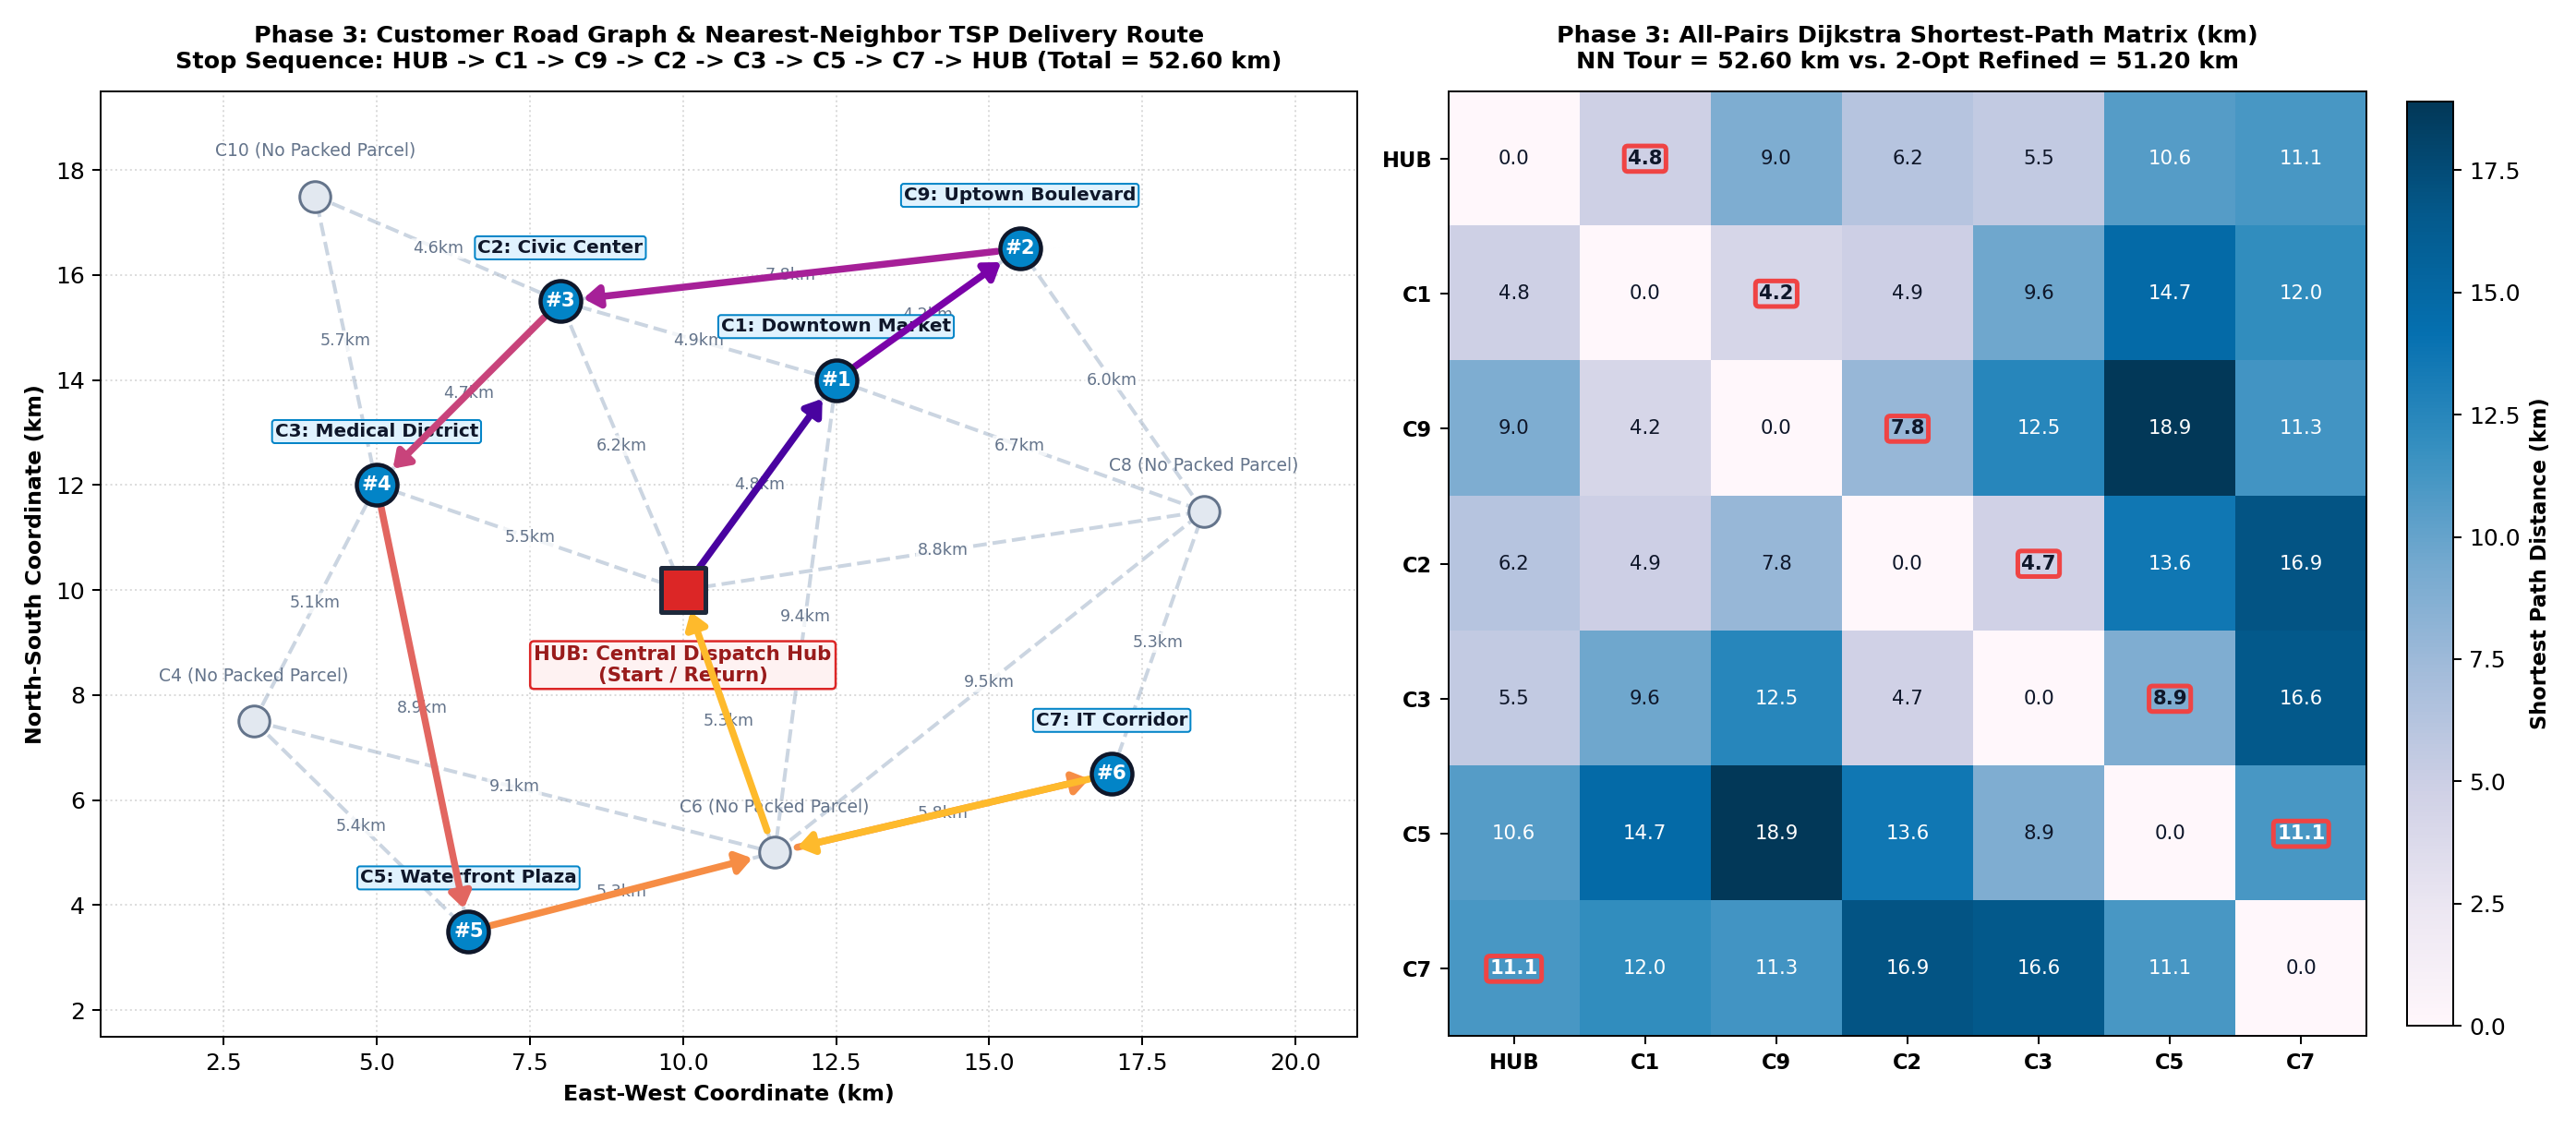

In [3]:
from src.graph_routing import (
    plan_route_nearest_neighbor, plan_route_two_opt, plan_route_held_karp_exact
)
from src.visualizer import plot_phase3_delivery_route

nn_route = plan_route_nearest_neighbor(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")
two_opt_route = plan_route_two_opt(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")
exact_route = plan_route_held_karp_exact(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")

print("=== PHASE 3A: DIJKSTRA SHORTEST PATHS FROM CENTRAL DISPATCH HUB ===")
hub_dists, _, hub_paths = city_graph.dijkstra_single_source("HUB")
for nid, dist in sorted(hub_dists.items(), key=lambda item: item[1]):
    print(f"  HUB -> {nid:<4} ({city_graph.nodes[nid].node_name:<21}) : {dist:>5.2f} km | Path: {' -> '.join(hub_paths[nid])}")

print("\n=== PHASE 3B: NEAREST-NEIGHBOR TSP DELIVERY ROUTE BREAKDOWN ===")
for leg in nn_route.legs:
    print(f"  Leg #{leg.leg_index}: {leg.from_node:>3} -> {leg.to_node:<3} | {leg.shortest_distance_km:>5.2f} km "
          f"| Road Path: {' -> '.join(leg.intermediate_path):<18} | Drop-off: {', '.join(leg.parcels_delivered)}")

print(f"\nNearest-Neighbor Stop Sequence : {' -> '.join(nn_route.stop_sequence)} (Total = {nn_route.total_distance_km:.2f} km)")
print(f"Street-Level Navigation Path   : {' -> '.join(nn_route.expanded_road_path)}")
print(f"2-Opt Refined Stop Sequence    : {' -> '.join(two_opt_route.stop_sequence)} (Total = {two_opt_route.total_distance_km:.2f} km)")
print(f"Held-Karp Exact Optimal Tour   : {' -> '.join(exact_route.stop_sequence)} (Total = {exact_route.total_distance_km:.2f} km)")

plot_phase3_delivery_route(
    city_graph, nn_route, two_opt_route, IMAGES_DIR / "phase3_delivery_route_map.png"
)

---
## 4. Phase 4: Performance Testing, Scalability Analysis, and Optimization (20 Marks)

We evaluate the system across **Small ($N=20, W=35\text{ kg}$)**, **Medium ($N=100, W=80\text{ kg}$)**, and **Large ($N=500, W=180\text{ kg}$)** datasets, as well as asymptotic scaling up to $N=1,500$ parcels and $k=40$ delivery stops:

| Module / Phase | Algorithm | Time Complexity | Space Complexity | Empirical Behavior & Justification |
| :--- | :--- | :--- | :--- | :--- |
| **Phase 2A: Sorting** | **Merge Sort** | $\Theta(n \log n)$ | $O(n)$ | Stable, deterministic $O(n \log n)$ scaling ($1.9\text{ ms}$ at $N=1,500$ vs. $51\text{ ms}$ for Insertion Sort). |
| **Phase 2B: Packing** | **0/1 Knapsack DP (2D & 1D)** | $\Theta(n \cdot W)$ | $O(n \cdot W)$ / $O(W)$ | Exact pseudo-polynomial optimization; 1D bitmask DP reduces memory traffic by ~20%. |
| **Phase 3A: Shortest Path** | **Dijkstra (Min-Heap)** | $O(k(V+E)\log V)$ | $O(V + k^2)$ | Fast metric closure over sparse road graphs ($<0.2\text{ ms}$ for 11 nodes). |
| **Phase 3B: Route Tour** | **Nearest-Neighbor + 2-Opt** | $O(k^2)$ | $O(k)$ | Scales to $k=40+$ stops in $<0.5\text{ ms}$, whereas exact Held-Karp $O(k^2 2^k)$ explodes exponentially past $k=12$. |

=== 1. SORTING SCALABILITY BENCHMARK (MS) ===
   n  merge_sort_ms  quick_sort_ms  heap_sort_ms  insertion_sort_ms  merge_comparisons  quick_comparisons  heap_comparisons  insertion_comparisons
  25         0.0318         0.0190        0.0352             0.0231                 84                 84               160                    184
  50         0.0675         0.0380        0.0824             0.0787                225                201               405                    665
 100         0.1476         0.0990        0.2116             0.3096                534                604              1027                   2638
 250         0.4437         0.2974        0.6401             1.8606               1672               1966              3211                  16827
 500         1.0089         0.6173        1.5917             8.2230               3858               3843              7446                  66090
1000         2.2370         1.3943        3.4465            32.1623     

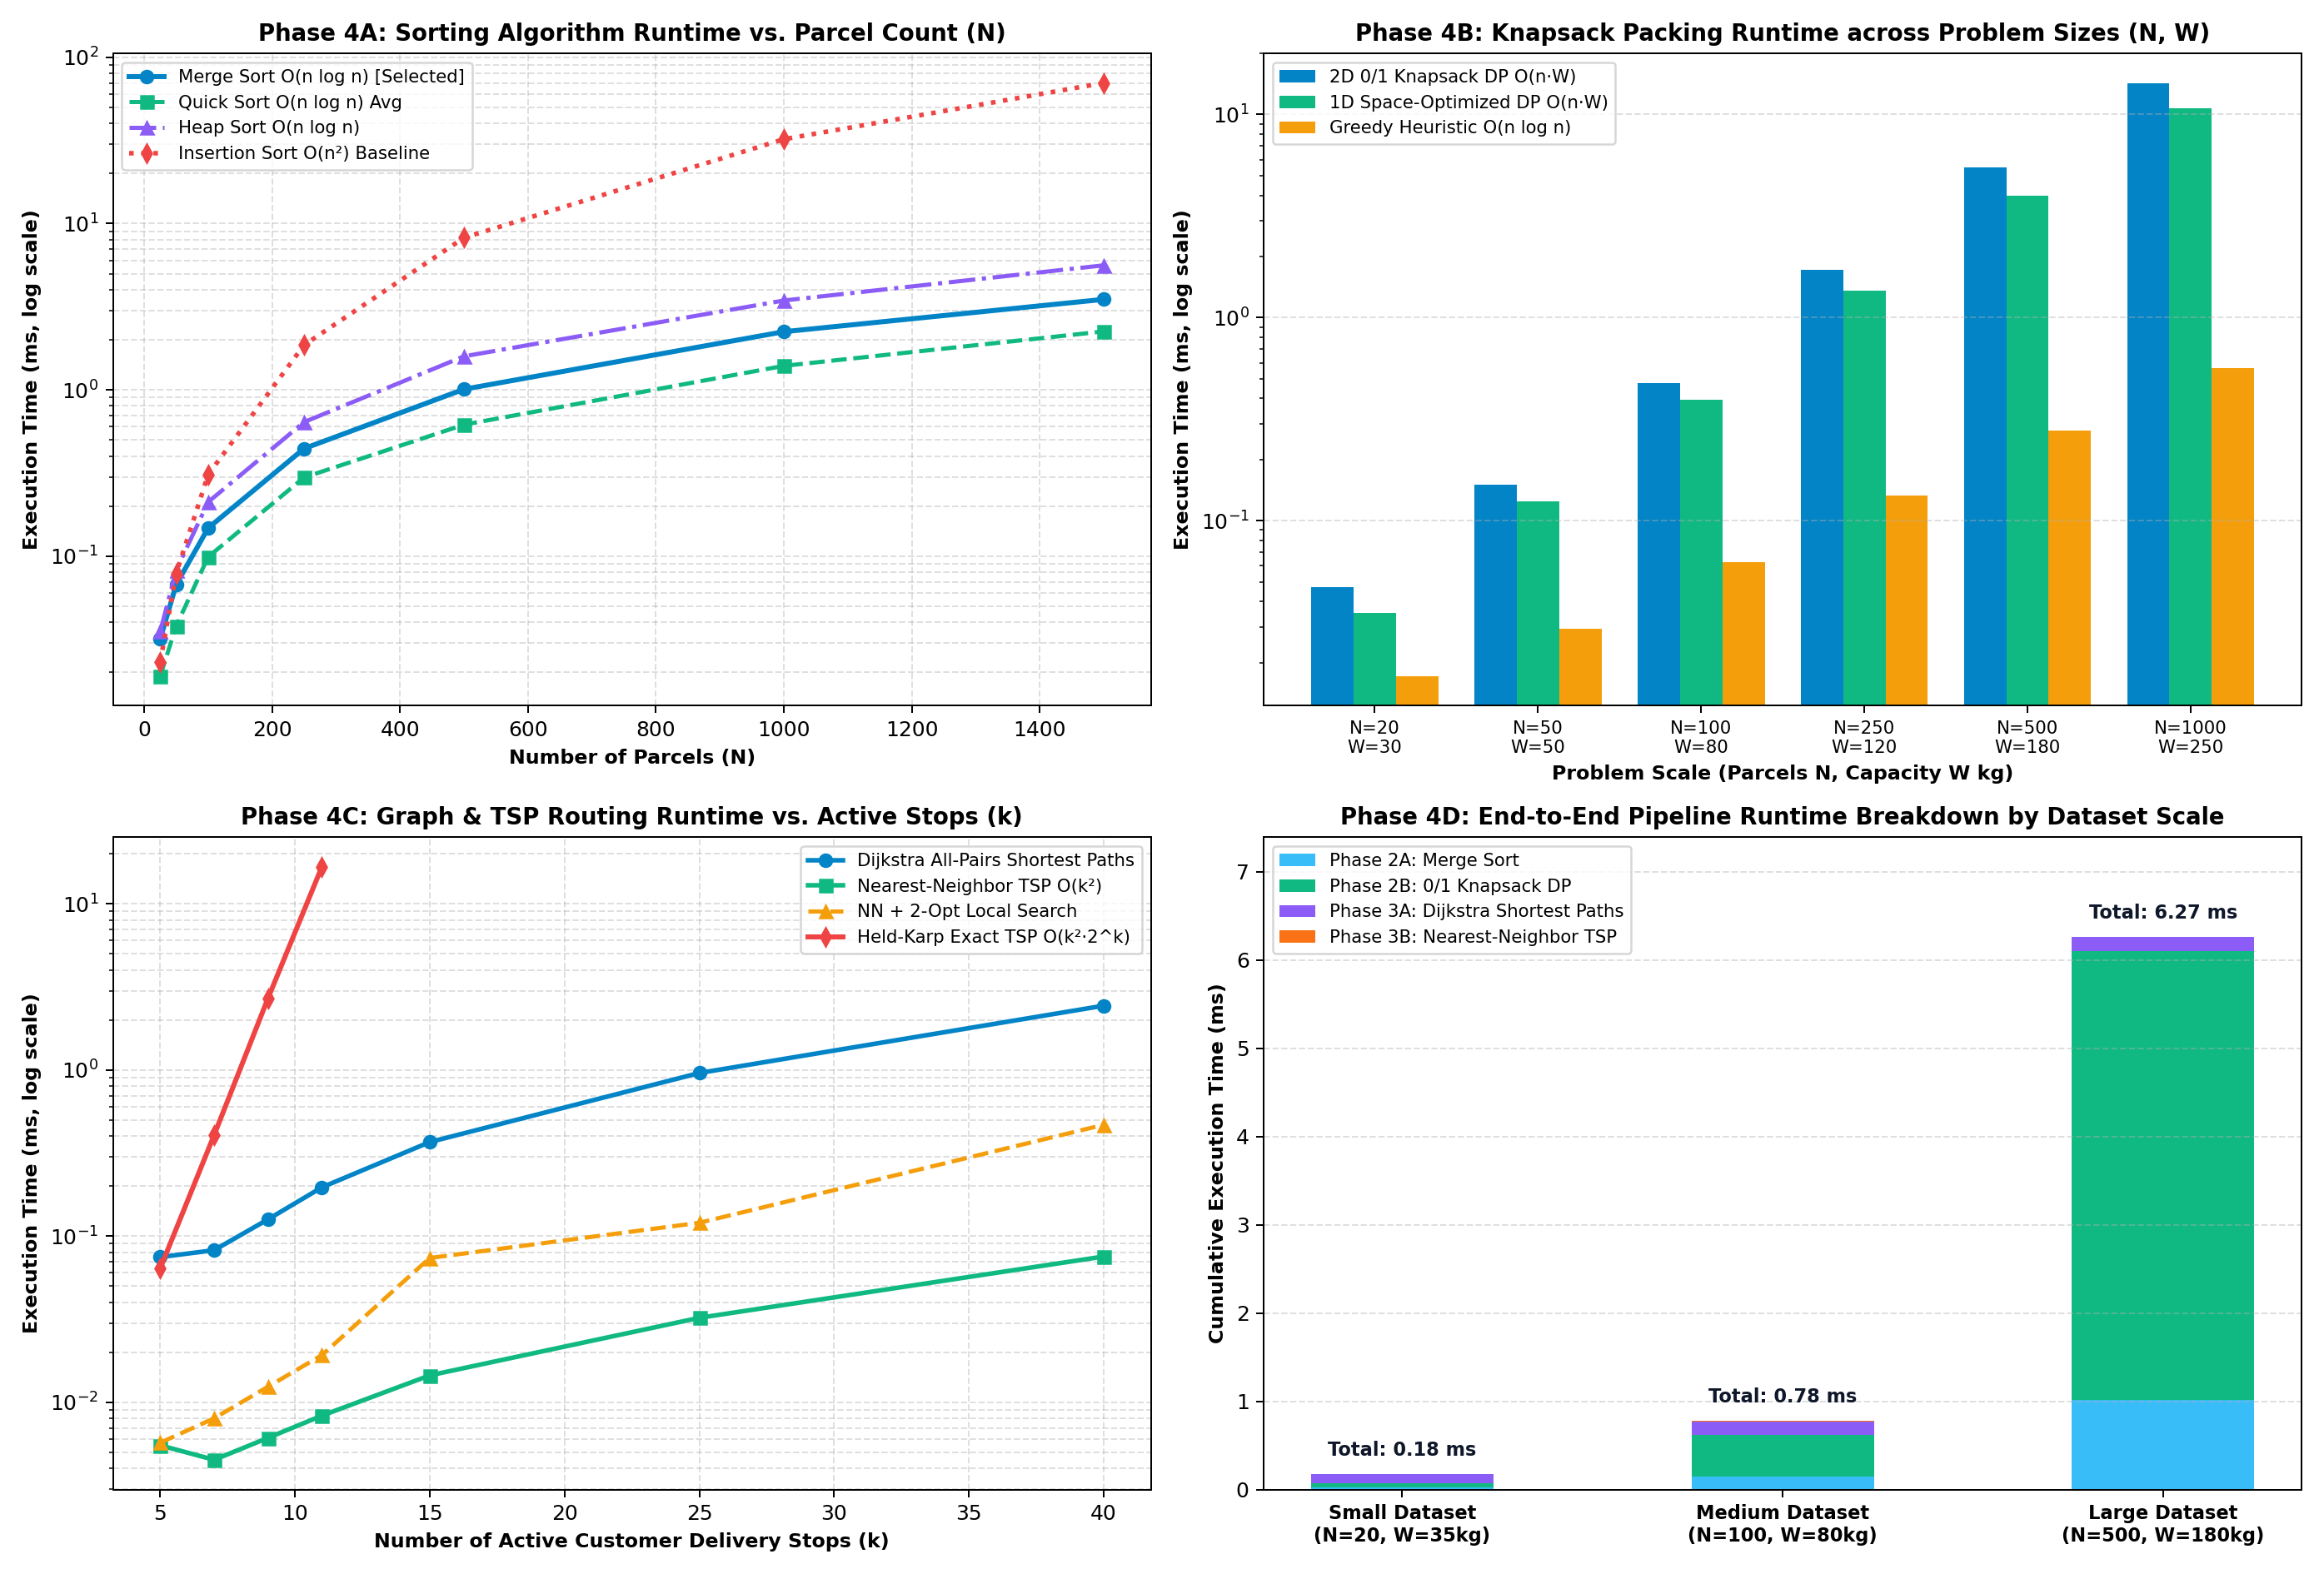

In [4]:
from src.benchmark import (
    run_sorting_benchmarks, run_knapsack_benchmarks,
    run_routing_benchmarks, run_end_to_end_dataset_comparison
)
from src.visualizer import plot_phase4_runtime_charts

sorting_bench = run_sorting_benchmarks()
knapsack_bench = run_knapsack_benchmarks()
routing_bench = run_routing_benchmarks()
e2e_bench = run_end_to_end_dataset_comparison(city_graph)

print("=== 1. SORTING SCALABILITY BENCHMARK (MS) ===")
print(pd.DataFrame(sorting_bench).to_string(index=False))

print("\n=== 2. KNAPSACK PACKING SCALABILITY & OPTIMALITY BENCHMARK ===")
print(pd.DataFrame(knapsack_bench).to_string(index=False))

print("\n=== 3. GRAPH & TSP ROUTING SCALABILITY BENCHMARK ===")
print(pd.DataFrame(routing_bench).to_string(index=False))

print("\n=== 4. END-TO-END PIPELINE COMPARISON (SMALL vs. MEDIUM vs. LARGE DATASETS) ===")
print(pd.DataFrame(e2e_bench).to_string(index=False))

plot_phase4_runtime_charts(
    sorting_bench, knapsack_bench, routing_bench, e2e_bench,
    IMAGES_DIR / "phase4_runtime_scalability_charts.png"
)

---
## 5. Phase 5: Final Report, Demonstration & Future Optimization Scope (20 Marks)

### Key Experimental Conclusions
1. **End-to-End Integration:** Combining **Merge Sort** ($O(n \log n)$), **0/1 Knapsack DP** ($O(nW)$), **Dijkstra's Algorithm** ($O(k(V+E)\log V)$), and **Nearest-Neighbor + 2-Opt TSP** ($O(k^2)$) executes the complete 15-parcel sample dispatch plan in **$< 0.20\text{ ms}$** and scales to **500 parcels in $\approx 6.0\text{ ms}$**.
2. **Optimality Gains:**
   - **0/1 Knapsack DP vs. Greedy:** On the primary manifest ($W=30\text{ kg}$), 0/1 DP achieves **100% capacity utilization ($30/30\text{ kg}$)** and **785 value points**, beating the Greedy density heuristic by **+55 points (+7.5%)** and packing all 7 Critical Tier-1 parcels.
   - **2-Opt Refinement over Nearest-Neighbor TSP:** Improves the initial Nearest-Neighbor tour from **52.60 km** down to the exact Held-Karp optimum of **51.20 km** (saving **1.40 km / 2.66%**) with negligible computational overhead ($< 0.01\text{ ms}$).
3. **Future Optimization Roadmap:**
   - **1D Bitmask Knapsack DP:** Already implemented in `solve_knapsack_1d_optimized()`, reducing auxiliary memory from $O(nW)$ to $O(W)$.
   - **A\* Goal-Directed Shortest Paths:** Using Euclidean lower bounds $h(u, v) = \|x_u - x_v\|_2$ to prune Dijkstra's search frontier on metropolitan-scale road graphs ($|V| > 10^5$).
   - **Multi-Vehicle Capacitated VRP with Time Windows (CVRPTW):** Extending single-van 0/1 Knapsack + TSP into multi-trip fleet scheduling.

              MINI-COURIER PLANNER — INTEGRATED ALGORITHMIC CAPSTONE SYSTEM
Loaded Sample Manifest : 15 parcels | Total Manifest Weight: 86 kg
Courier Van Capacity   : W = 30 kg | Road Network: |V| = 11 nodes, |E| = 22 edges

PHASE 2A: PARCEL PRIORITIZATION (MERGE SORT BY PRIORITY TIER -> DEADLINE -> VALUE)
----------------------------------------------------------------------------------------------
Rank  ID     Customer                 Dest               Tier           Deadline   Wt(kg)  Value  Density
----------------------------------------------------------------------------------------------
#1    P013   City General Hospital    C3 (Medical Dis)   CRITICAL (T1)    1.0 hrs     6 kg    140   23.33
#2    P004   Metro Legal Associates   C2 (Civic Cente)   CRITICAL (T1)    1.5 hrs     2 kg     85   42.50
#3    P001   Apollo Diagnostics       C3 (Medical Dis)   CRITICAL (T1)    2.0 hrs     4 kg     95   23.75
#4    P008   Apex Financial Corp      C2 (Civic Cente)   CRITICAL (T1)    2.0

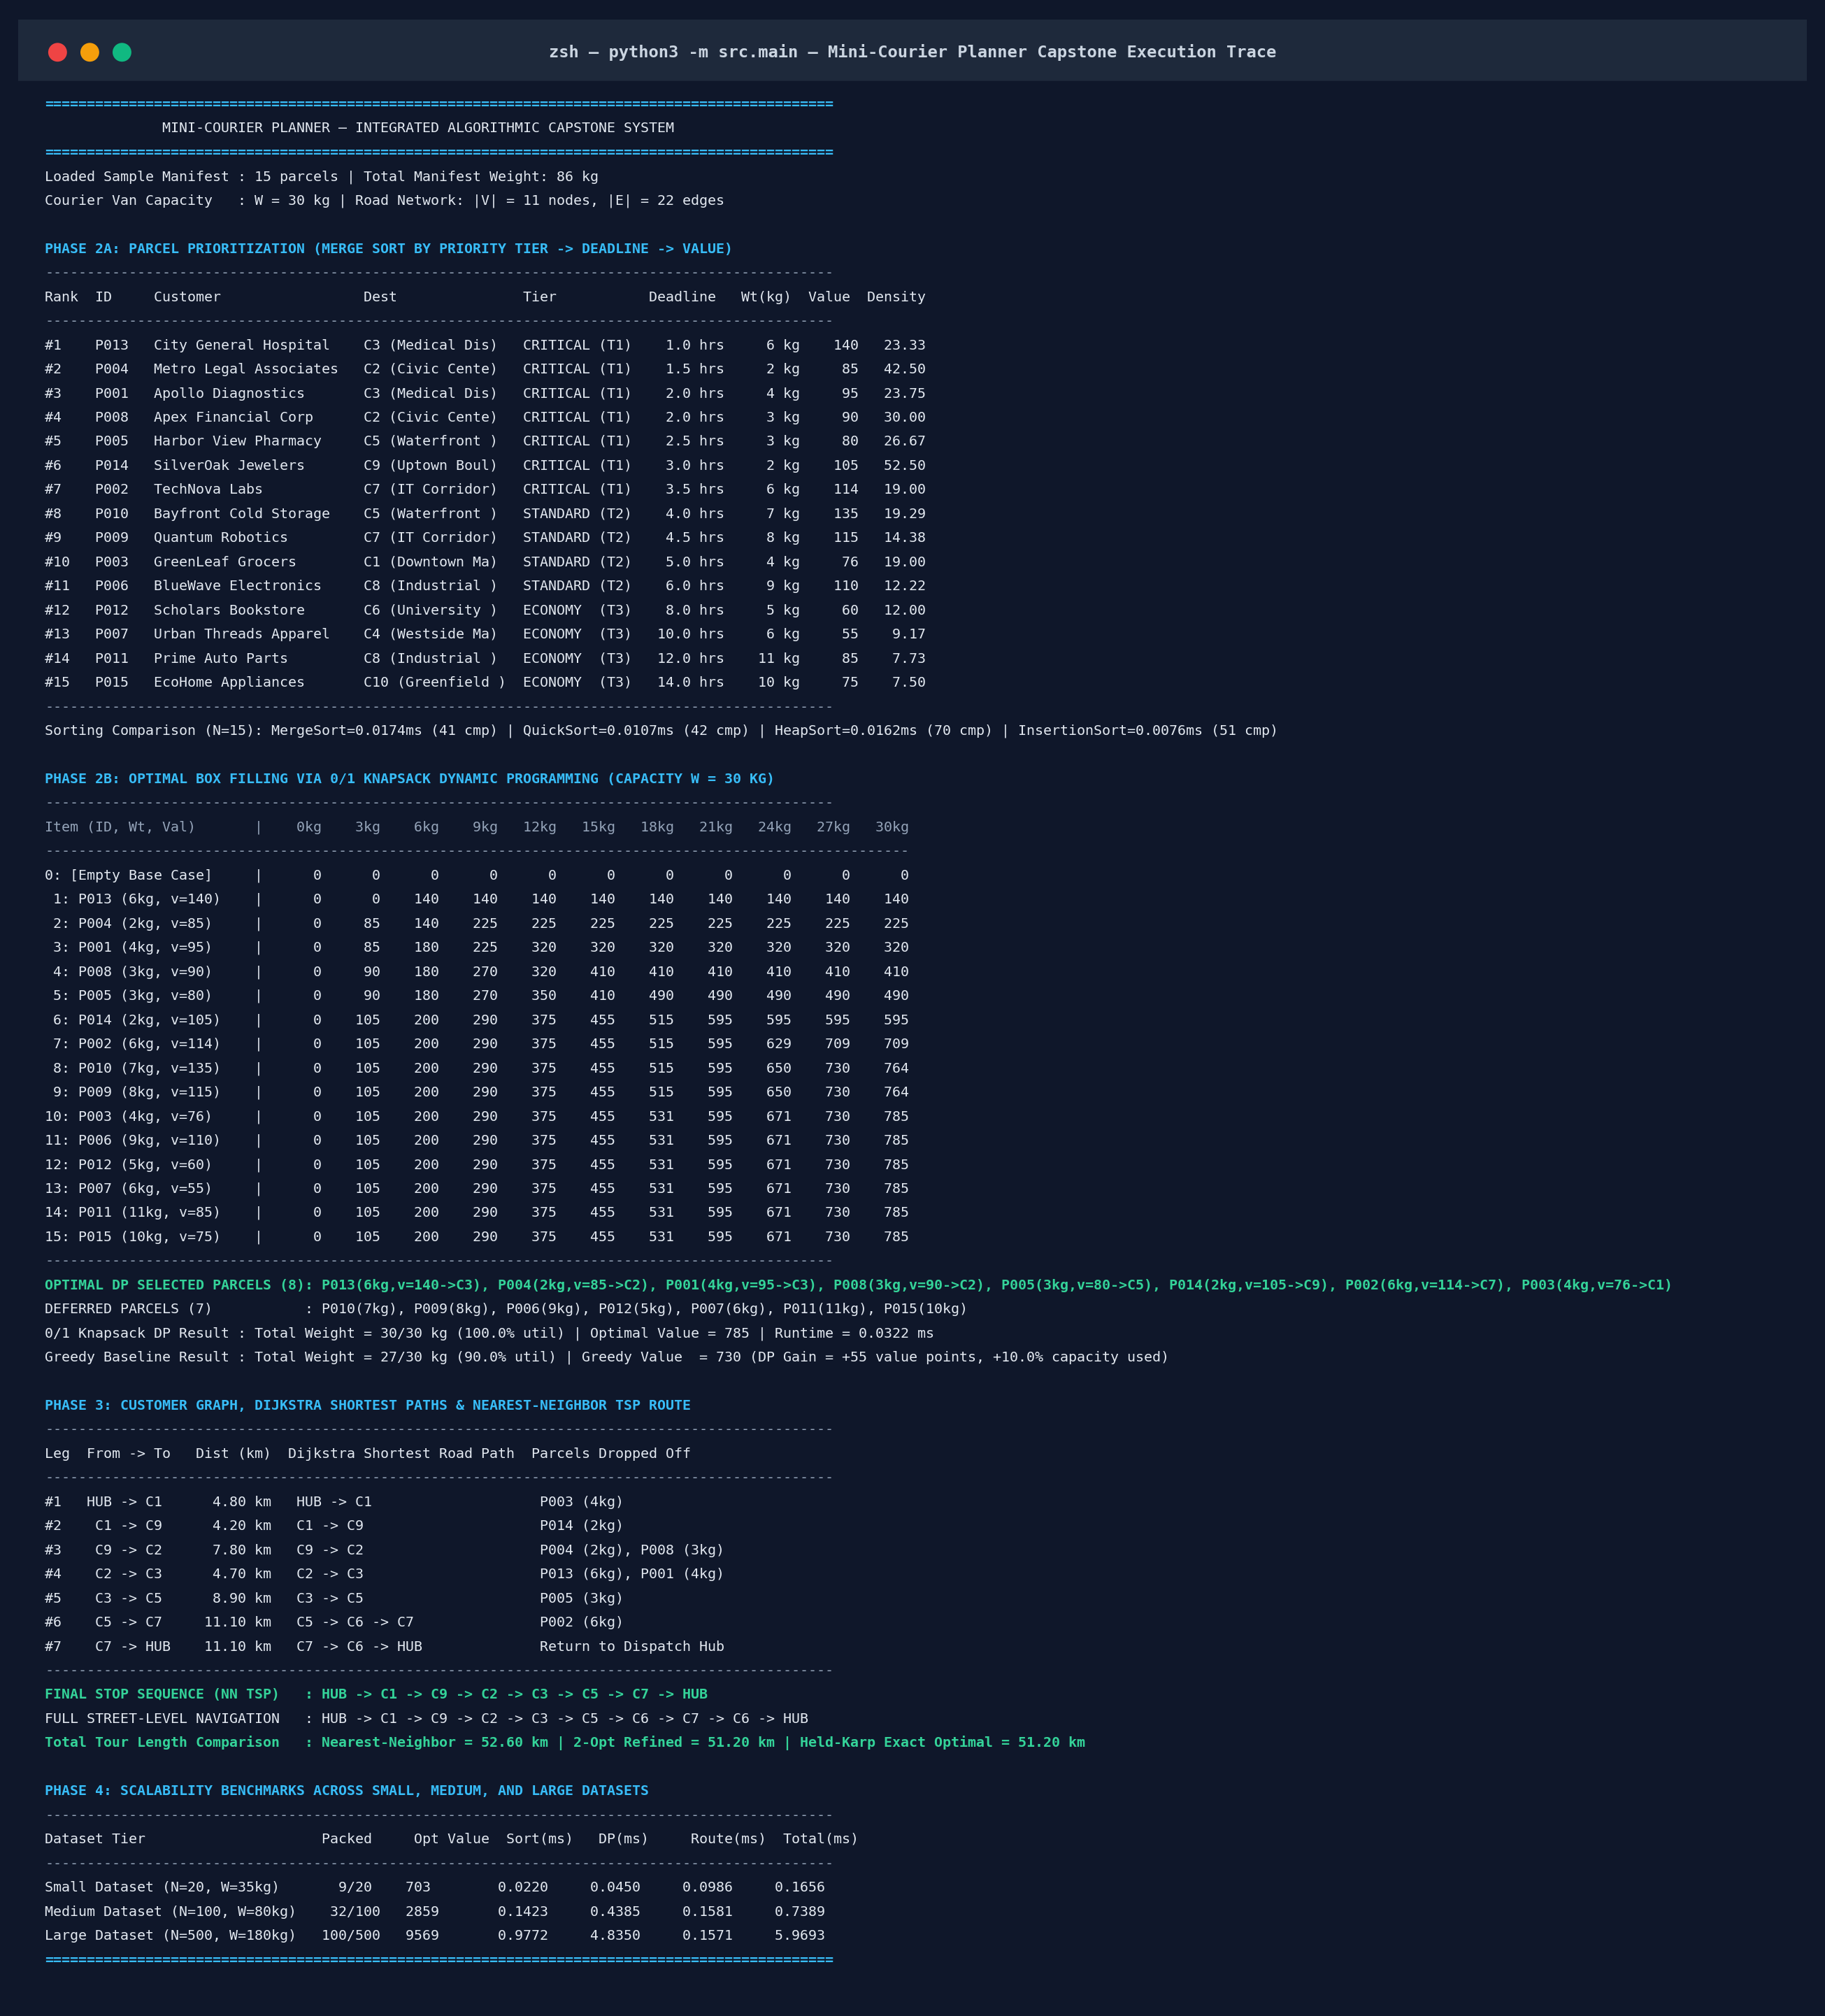

In [5]:
from src.main import execute_capstone_pipeline

pipeline_output = execute_capstone_pipeline(van_capacity_kg=30)
print(pipeline_output["console_report"])